Look at the data

In [1]:
import pandas as pd
df = pd.read_csv("nvda_data.csv")
print(df.columns)
df.head()

Index(['Date', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='str')


,Date,Close,High,Low,Open,Volume
0,2016-01-04,0.787744,0.792855,0.779714,0.785797,358076000
1,2016-01-05,0.800399,0.813784,0.790908,0.802589,490272000
2,2016-01-06,0.767303,0.790908,0.758298,0.787258,449344000
3,2016-01-07,0.736883,0.753188,0.727149,0.748078,645304000
4,2016-01-08,0.721065,0.747104,0.719605,0.746374,398472000


Made this Date column into the datetime datatype & made Date column as an Index 

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt

#Load csv data we save earlier
df = pd.read_csv("nvda_data.csv")

#Convert date column to actual datetime type (omportant for time series work)
df['Date'] = pd.to_datetime(df['Date'])

#Set date as the index (standard practice for time series data)
df.set_index('Date', inplace=True)

print(df.shape)
df.head()

(2730, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2016-01-04,0.787744,0.792855,0.779714,0.785797,358076000
2016-01-05,0.800399,0.813784,0.790908,0.802589,490272000
2016-01-06,0.767303,0.790908,0.758298,0.787258,449344000
2016-01-07,0.736883,0.753188,0.727149,0.748078,645304000
2016-01-08,0.721065,0.747104,0.719605,0.746374,398472000


Show How NVDA data looks like

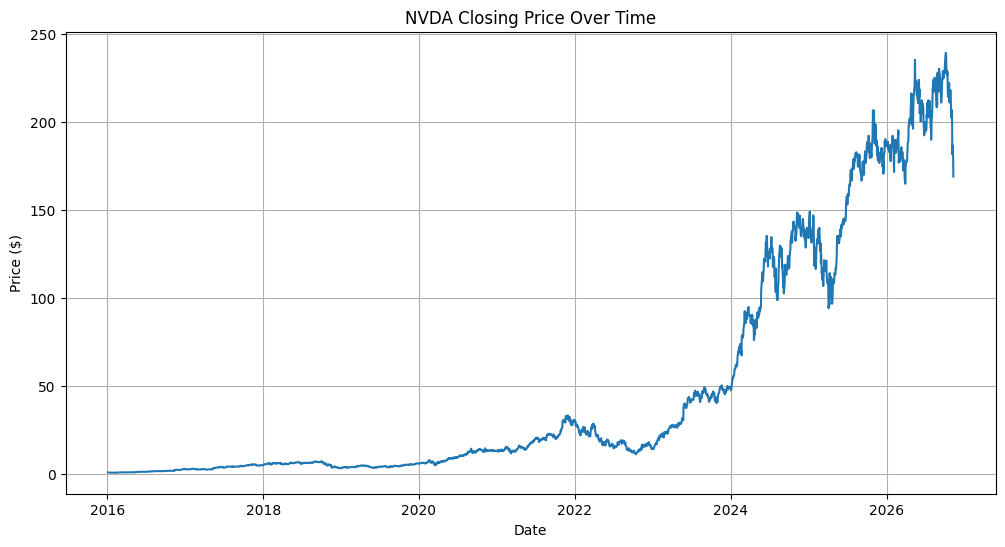

In [3]:
plt.figure(figsize=(12,6))
plt.plot(df.index, df['Close'])
plt.title('NVDA Closing Price Over Time')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.grid(True)
plt.show()

Calculate daily returns in %


In [4]:
print(df.columns.tolist())

['Close', 'High', 'Low', 'Open', 'Volume']


In [5]:
# 2. Return
df['Return'] = df['Close'].pct_change()

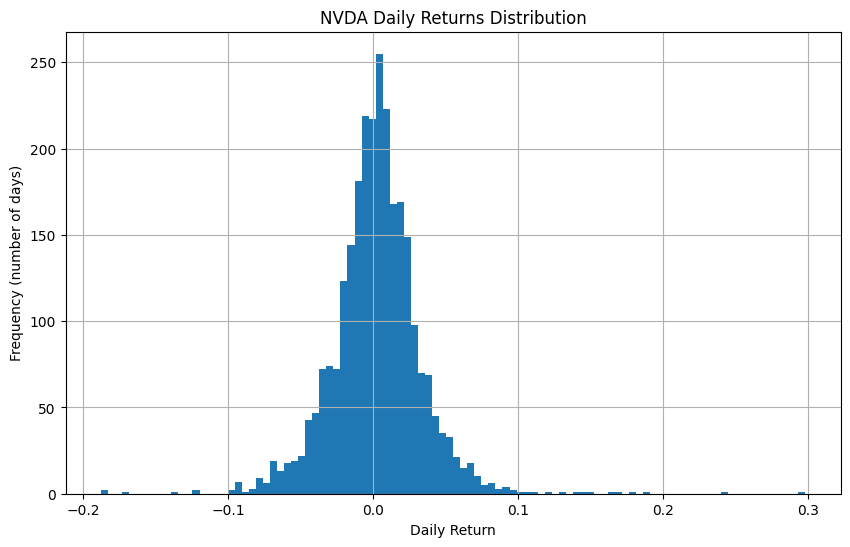

In [6]:
plt.figure(figsize=(10,6))
plt.hist(df['Return'], bins=100)
plt.title('NVDA Daily Returns Distribution')
plt.xlabel('Daily Return')
plt.ylabel('Frequency (number of days)')
plt.grid(True)
plt.show()

In [7]:
from statsmodels.tsa.stattools import adfuller

# Test on raw Close price
result_price = adfuller(df['Close'])
print("ADF test on Close price:")
print(f"  Test Statistic: {result_price[0]:.4f}")
print(f"  p-value: {result_price[1]:.4f}")

# Test on Returns
result_return = adfuller(df['Return'].dropna())
print("\nADF test on Returns:")
print(f"  Test Statistic: {result_return[0]:.4f}")
print(f"  p-value: {result_return[1]:.4f}")

ADF test on Close price:
  Test Statistic: -0.2469
  p-value: 0.9327

ADF test on Returns:
  Test Statistic: -18.7683
  p-value: 0.0000


In [8]:
# Moving averages
df['MA5'] = df['Close'].rolling(window=5).mean()
df['MA10'] = df['Close'].rolling(window=10).mean()
df['MA20'] = df['Close'].rolling(window=20).mean()

df[['Close', 'MA5', 'MA10', 'MA20']].tail(10)

,Close,MA5,MA10,MA20
Date,,,,
2026-10-28,215.380005,214.498004,215.938002,223.785001
2026-10-29,213.660004,214.788004,215.581003,222.925002
2026-10-30,204.639999,213.524002,214.632002,221.459502
2026-11-02,202.059998,210.736002,213.129002,219.617502
2026-11-03,206.690002,208.486002,212.151003,217.990002
2026-11-04,200.130005,205.436002,209.967003,216.123002
2026-11-05,181.600006,199.024002,206.906003,213.679002
2026-11-06,186.639999,195.424002,204.474002,211.547002
2026-11-09,178.669998,190.746002,200.741002,209.164502


In [9]:
def calculate_rsi(prices, window=14):
    delta = prices.diff()
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    
    avg_gain = gain.rolling(window=window).mean()
    avg_loss = loss.rolling(window=window).mean()
    
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

df['RSI'] = calculate_rsi(df['Close'])

df[['Close', 'RSI']].tail(10)

,Close,RSI
Date,,
2026-10-28,215.380005,35.013891
2026-10-29,213.660004,34.656182
2026-10-30,204.639999,30.969086
2026-11-02,202.059998,26.927088
2026-11-03,206.690002,36.657530
2026-11-04,200.130005,35.062895
2026-11-05,181.600006,27.617995
2026-11-06,186.639999,29.632105
2026-11-09,178.669998,26.979289


In [10]:
# Rolling volatility = standard deviation of daily returns over a window
df['Volatility10'] = df['Return'].rolling(window=10).std()
df['Volatility20'] = df['Return'].rolling(window=20).std()

df[['Close', 'Return', 'Volatility10', 'Volatility20']].tail(10)

,Close,Return,Volatility10,Volatility20
Date,,,,
2026-10-28,215.380005,-0.011746,0.021296,0.019122
2026-10-29,213.660004,-0.007986,0.020678,0.018879
2026-10-30,204.639999,-0.042217,0.024192,0.020274
2026-11-02,202.059998,-0.012608,0.023429,0.019231
2026-11-03,206.690002,0.022914,0.025268,0.020362
2026-11-04,200.130005,-0.031738,0.024238,0.021095
2026-11-05,181.600006,-0.092590,0.034504,0.028016
2026-11-06,186.639999,0.027753,0.037028,0.029342
2026-11-09,178.669998,-0.042703,0.035920,0.030249


In [11]:
print("Rows before dropping NaNs:", df.shape[0])

df.dropna(inplace=True)

print("Rows after dropping NaNs:", df.shape[0])
df.head()

Rows before dropping NaNs: 2730
Rows after dropping NaNs: 2710


,Close,High,Low,Open,Volume,Return,MA5,MA10,MA20,RSI,Volatility10,Volatility20
Date,,,,,,,,,,,,
2016-02-02,0.682858,0.709384,0.677991,0.705734,341908000,-0.042321,0.696291,0.690913,0.706305,36.514066,0.022933,0.025690
2016-02-03,0.686265,0.692349,0.670447,0.688212,326772000,0.004989,0.695512,0.692665,0.700599,42.514107,0.022927,0.025288
2016-02-04,0.686508,0.702083,0.679694,0.687238,348140000,0.000355,0.696291,0.693663,0.696559,46.461538,0.022721,0.024025
2016-02-05,0.643191,0.689428,0.641244,0.681884,600428000,-0.063098,0.682371,0.688747,0.691874,44.940438,0.029110,0.026260
2016-02-08,0.613745,0.636620,0.604741,0.633457,608852000,-0.045781,0.662513,0.680960,0.686508,36.316554,0.031446,0.027524


In [12]:
# Target: 1 if tomorrow's close is higher than today's, else 0
df['Target'] = (df['Close'].shift(-1) > df['Close']).astype(int)

df[['Close', 'Target']].tail(10)

,Close,Target
Date,,
2026-10-28,215.380005,0
2026-10-29,213.660004,0
2026-10-30,204.639999,0
2026-11-02,202.059998,1
2026-11-03,206.690002,0
2026-11-04,200.130005,0
2026-11-05,181.600006,1
2026-11-06,186.639999,0
2026-11-09,178.669998,0


In [13]:
print(df.columns.tolist())

['Close', 'High', 'Low', 'Open', 'Volume', 'Return', 'MA5', 'MA10', 'MA20', 'RSI', 'Volatility10', 'Volatility20', 'Target']


In [14]:
df_model = df.dropna(subset=['Target']).copy()

feature_cols = ['Return', 'MA5', 'MA10', 'MA20', 'RSI', 'Volatility10', 'Volatility20']
X = df_model[feature_cols]
y = df_model['Target']

split_index = int(len(df_model) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)
print("\nTrain date range:", df_model.index[0], "to", df_model.index[split_index-1])
print("Test date range:", df_model.index[split_index], "to", df_model.index[-1])

Train size: (2168, 7)
Test size: (542, 7)

Train date range: 2016-02-02 00:00:00 to 2024-09-12 00:00:00
Test date range: 2024-09-13 00:00:00 to 2026-11-10 00:00:00


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Train baseline model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict on test set
y_pred = model.predict(X_test)

# Evaluate
accuracy = accuracy_score(y_test, y_pred)
print(f"Baseline Logistic Regression Accuracy: {accuracy:.4f}")

# Compare to naive baseline: "always predict the majority class"
naive_baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Naive baseline (always predict majority class): {naive_baseline:.4f}")

Baseline Logistic Regression Accuracy: 0.4668
Naive baseline (always predict majority class): 0.5203


In [22]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[ 88 172]
 [117 165]]
              precision    recall  f1-score   support

           0       0.43      0.34      0.38       260
           1       0.49      0.59      0.53       282

    accuracy                           0.47       542
   macro avg       0.46      0.46      0.46       542
weighted avg       0.46      0.47      0.46       542



Random Forest Accuracy

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

rf = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Random Forest accuracy:", accuracy_score(y_test, rf_pred))
print("Naive baseline:", max(y_test.mean(), 1 - y_test.mean()))
print(confusion_matrix(y_test, rf_pred))

Random Forest accuracy: 0.5055350553505535
Naive baseline: 0.5202952029520295
[[234  26]
 [242  40]]


In [24]:
import pandas as pd
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(imp)

Return          0.152746
Volatility20    0.148617
Volatility10    0.146347
RSI             0.145253
MA5             0.142874
MA10            0.136059
MA20            0.128103
dtype: float64


Buy & hold final value: 1.422
Strategy final value:   1.487


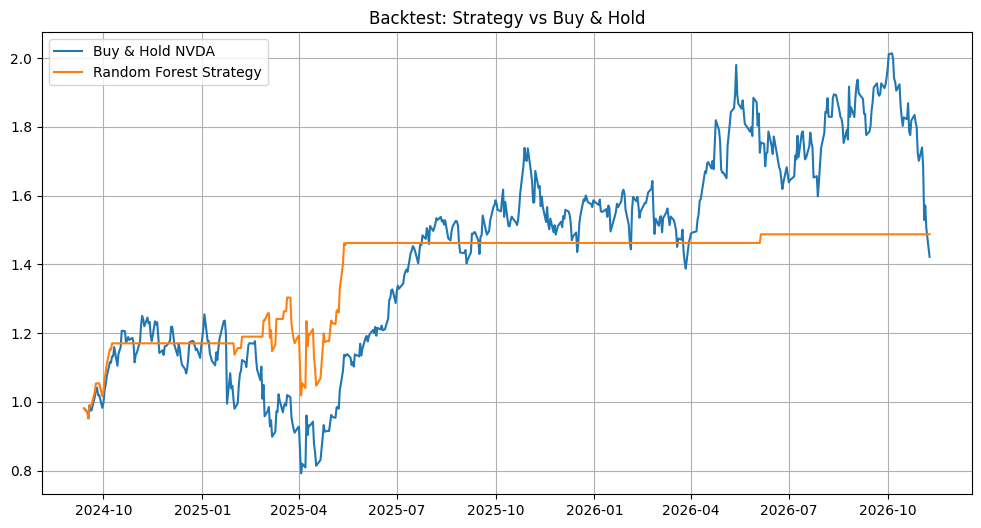

In [25]:
import matplotlib.pyplot as plt

# Test-period data
test_df = df.iloc[split_index:].copy()

# Next-day return (what you actually earn if you hold tomorrow)
test_df['Next_Return'] = test_df['Return'].shift(-1)

# Strategy: hold NVDA only on days the model says UP
test_df['Signal'] = rf_pred
test_df['Strategy_Return'] = test_df['Signal'] * test_df['Next_Return']

test_df = test_df.dropna(subset=['Next_Return'])

# Cumulative growth of 1 dollar
buy_hold = (1 + test_df['Next_Return']).cumprod()
strategy = (1 + test_df['Strategy_Return']).cumprod()

print("Buy & hold final value:", round(buy_hold.iloc[-1], 3))
print("Strategy final value:  ", round(strategy.iloc[-1], 3))

plt.figure(figsize=(12,6))
plt.plot(buy_hold, label='Buy & Hold NVDA')
plt.plot(strategy, label='Random Forest Strategy')
plt.title('Backtest: Strategy vs Buy & Hold')
plt.legend()
plt.grid(True)
plt.show()